# Homework 5 - question 3 - part d

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import fftconvolve

In [12]:
# Spatial and temporal discretization
dx = 0.02
dt = 0.02
x = np.arange(-20, 20 + dx / 2, dx)
w = 2 * np.exp(-np.abs(x)) - np.exp(-np.abs(x) / 2)

def W(x):
    """Odd antiderivative of the even kernel w."""
    return np.sign(x) * 2 * (
        np.exp(-np.abs(x) / 2) - np.exp(-np.abs(x))
    )

def bump_widths(kappa):
    S = np.sqrt(1 - 2 * kappa)
    a_narrow = -np.log((1 + S) / 2)
    a_wide = -np.log((1 - S) / 2)
    return a_narrow, a_wide

def simulate(kappa, a0, T=100.0):
    """Simulate from U(x,0)=W(x+a0)-W(x-a0)."""
    U = W(x + a0) - W(x - a0)
    nsteps = int(T / dt)
    times = np.arange(nsteps + 1) * dt
    widths = np.empty(nsteps + 1)

    
    def measure_width(u):
        # Find the center of the spatial grid
        mid = len(x) // 2
    
        # Find the first point below threshold to the right
        crossings = np.flatnonzero(u[mid:] < kappa)
    
        if len(crossings) == 0:
            return np.nan
    
        j = mid + crossings[0]
    
        if j == mid:
            return np.nan
    
        # Linear interpolation between the two grid points
        x1, x2 = x[j-1], x[j]
        u1, u2 = u[j-1], u[j]
    
        crossing = x1 + (kappa - u1) * (x2 - x1) / (u2 - u1)
    
        return crossing


    widths[0] = measure_width(U)

    for i in range(nsteps):
        active = (U >= kappa).astype(float)
        convolution = fftconvolve(active, w, mode="same") * dx
        U += dt * (-U + convolution)
        widths[i + 1] = measure_width(U)

    return times, widths

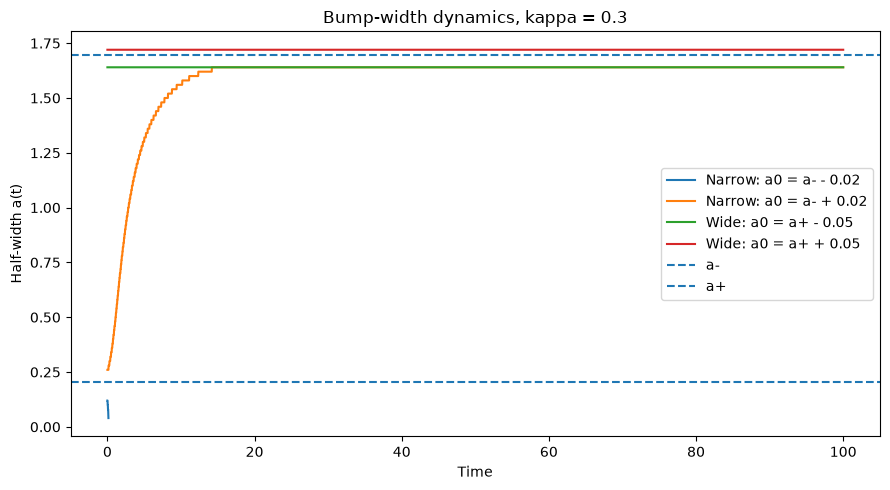

In [7]:
# Part (d), kappa = 0.3
kappa = 0.3
a_minus, a_plus = bump_widths(kappa)

cases = [
    (a_minus - 0.02, "Narrow: a0 = a- - 0.02"),
    (a_minus + 0.02, "Narrow: a0 = a- + 0.02"),
    (a_plus - 0.05, "Wide: a0 = a+ - 0.05"),
    (a_plus + 0.05, "Wide: a0 = a+ + 0.05"),
]

plt.figure(figsize=(9, 5))
for a0, label in cases:
    t, a = simulate(kappa, a0)
    plt.plot(t, a, label=label)

plt.axhline(a_minus, linestyle="--", label="a-")
plt.axhline(a_plus, linestyle="--", label="a+")
plt.xlabel("Time")
plt.ylabel("Half-width a(t)")
plt.title("Bump-width dynamics, kappa = 0.3")
plt.legend()
plt.tight_layout()
plt.show()

The narrow bump started at -0.02 completly died (it is not very visible near (0,0)); it became narrower and disappeared. The narrow bump started at +0.02 widened to the a+ half-width. Both the a+ +- 0.05 returned to the a+ line and didn't die or run away.

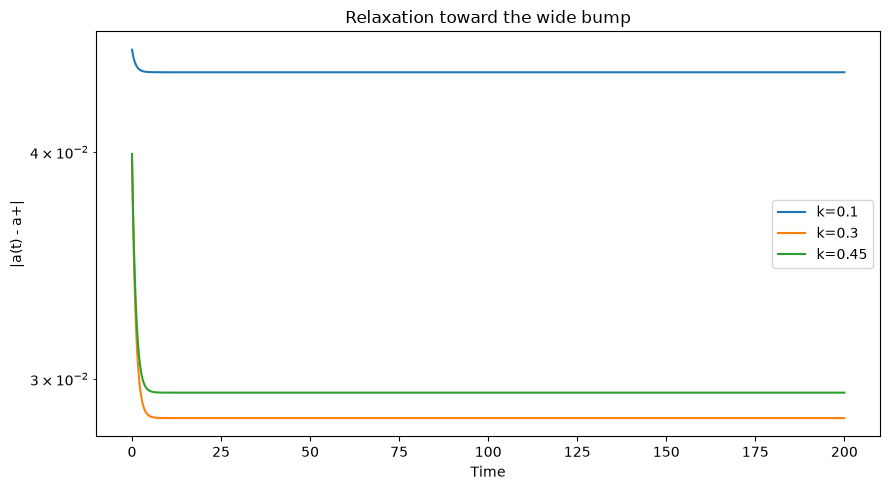

Estimated relaxation rates:
kappa=0.10: rate=-0.00000, |lambda_e|=0.09017
kappa=0.30: rate=-0.00000, |lambda_e|=0.20825
kappa=0.45: rate=-0.00000, |lambda_e|=0.19513


In [14]:
# Relaxation of the wide bump for three thresholds
plt.figure(figsize=(9, 5))
relaxation_rates = {}

for kappa in [0.1, 0.3, 0.45]:
    _, a_plus = bump_widths(kappa)
    t, a = simulate(kappa, a_plus + 0.05, T=200.0)
    error = np.abs(a - a_plus)

    valid = np.isfinite(error) & (error > 0)
    # Fit only the late-time region where the error is small
    late = valid & (t >= 0.25 * t[-1]) & (t <= 0.8 * t[-1])
    if np.count_nonzero(late) >= 5:
        slope, intercept = np.polyfit(t[late], np.log(error[late]), 1)
        relaxation_rates[kappa] = -slope
        plt.plot(t[valid], error[valid], label=f"k={kappa}")

plt.yscale("log")
plt.xlabel("Time")
plt.ylabel("|a(t) - a+|")
plt.title("Relaxation toward the wide bump")
plt.legend()
plt.tight_layout()
plt.show()

print("Estimated relaxation rates:")
for kappa, rate in relaxation_rates.items():
    S = np.sqrt(1 - 2 * kappa)
    lam_abs = S * (1 - S) / (1 + S * (1 - S) / 2)
    print(
        f"kappa={kappa:.2f}: rate={rate:.5f}, "
        f"|lambda_e|={lam_abs:.5f}"
    )